# Hyperparameter study: IQL on HalfCheetah and Hopper

Sensitivity of offline IQL to the discount factor $\gamma$ and the inverse temperature $\beta$ of the policy extraction step, on Minari `mujoco/halfcheetah/medium-v0` and `mujoco/hopper/medium-v0`.

## Design
- **One factor at a time** around the default configuration ($\gamma = 0.99$, $\beta = 3$, expectile $\tau = 0.7$):
  $\gamma \in \{0.95, 0.99, 0.995\}$ with $\beta = 3$, and $\beta \in \{1, 3, 10\}$ with $\gamma = 0.99$. Five settings per task.
- **Training.** Offline IQL, `STEPS` gradient steps per setting (default $10^6$), 3 seeds trained in parallel; all other hyperparameters as in `configs/<task>.yaml`.
- **Evaluation.** As in the task notebooks: 10 episodes per seed every 50,000 steps during training, and a final test of 20 episodes per seed with the mean action.

## Role of the two parameters
- $\gamma$ sets the effective horizon $1/(1-\gamma)$ of the value estimates: about 20, 100 and 200 steps for the three values. It enters the TD target $r + \gamma (1-d) V(s')$.
- $\beta$ sets how strongly the policy prefers high-advantage dataset actions in $\min(e^{\beta (\hat Q - V)}, 100)\, \log \pi(a \mid s)$; $\beta \to 0$ recovers behavior cloning.

## Output
`results/ablation/<task>/<setting>.json` (one file per setting, written when the setting finishes; existing files are skipped, so the sweep can be resumed after an interruption) and figures in `results/ablation/figures/`. Approximate cost on a T4 GPU: 18–20 minutes per setting at $10^6$ steps, about 3 hours for both tasks.

## 1. Setup

In [1]:
import os, sys, shutil
PROJECT_DIR = "/content/drive/MyDrive/offline-rl-jax"
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    PROJECT_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)
if shutil.which("nvidia-smi"):
    os.environ["MUJOCO_GL"] = "egl"
print("project folder:", PROJECT_DIR)

Mounted at /content/drive
project folder: /content/drive/MyDrive/offline-rl-jax


In [2]:
!pip install -q -r requirements-colab.txt

In [3]:
import jax
for _m in [m for m in sys.modules if m == "offrl" or m.startswith("offrl.")]:
    del sys.modules[_m]
import offrl
from offrl import ablation, plotting, save_json
print("offrl", offrl.__version__, "from", os.path.dirname(offrl.__file__))
print("JAX", jax.__version__, "| devices:", jax.devices())

offrl 0.3.0 from /content/drive/MyDrive/offline-rl-jax/offrl
JAX 0.11.1 | devices: [CudaDevice(id=0)]


## 2. Settings

In [4]:
TASKS = {"HalfCheetah": "configs/halfcheetah_medium.yaml", "Hopper": "configs/hopper_medium.yaml"}
DEFAULTS = {"discount": 0.99, "beta": 3.0}
VALUES = {"discount": [0.95, 0.99, 0.995], "beta": [1.0, 3.0, 10.0]}
STEPS = 1_000_000                                   # IQL gradient steps per setting
OUT_DIR = "results/ablation"

SETTINGS = ablation.one_at_a_time(VALUES, DEFAULTS)
for s in SETTINGS:
    print(ablation.setting_key(s))

beta3_discount0.99
beta3_discount0.95
beta3_discount0.995
beta1_discount0.99
beta10_discount0.99


## 3. Sweep
Trains and evaluates every setting that has no result file yet.

In [5]:
RESULTS = {}
for name, config_file in TASKS.items():
    print(f"\n===== {name} =====")
    RESULTS[name] = ablation.run_sweep(config_file, SETTINGS, f"{OUT_DIR}/{name.lower()}",
                                       overrides={"iql_steps": STEPS})


===== HalfCheetah =====


namespace_metadata.json:   0%|          | 0.00/1.31k [00:00<?, ?B/s]

metadata.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/1.86k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

namespace_metadata.json:   0%|          | 0.00/3.26k [00:00<?, ?B/s]

... (11 outputs left out)

namespace_metadata.json:   0%|          | 0.00/110 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]


Dataset mujoco/hopper/medium-v0 downloaded to /root/.minari/datasets/mujoco/hopper/medium-v0
task: mujoco/hopper/medium-v0 (mujoco) | 1,327 episodes, 999,404 steps | test episodes: 1000 steps | metric: return
999,404 transitions | reward scale 0.3909 | terminal in 641 of them (0.06%)
[1/5] beta3_discount0.99: training IQL for 1,000,000 steps
[IQL] step    50,000 | q_loss 0.416 | V    91.43 | return [1593 3525 1671] (mean 2263) | pct_data [56.5 125.1 59.3] (mean 80.3) | train 63s, total 69s
[IQL] step   100,000 | q_loss 0.328 | V   137.95 | return [3599 3467 3186] (mean 3417) | pct_data [127.7 123.0 113.1] (mean 121.3) | train 122s, total 133s
[IQL] step   150,000 | q_loss 0.230 | V   141.28 | return [1475 2575 1776] (mean 1942) | pct_data [52.4 91.4 63.0] (mean 68.9) | train 180s, total 195s
[IQL] step   200,000 | q_loss 0.197 | V   141.78 | return [3568 1421 3560] (mean 2850) | pct_data [126.6 50.4 126.3] (mean 101.1) | train 238s, total 259s
[IQL] step   250,000 | q_loss 0.180 | V  

## 4. Summary
Final test, mean ± std over seeds, and the fraction of episodes that fell or stopped moving.

In [6]:
rows = {name: ablation.print_summary(name, res) for name, res in RESULTS.items()}
save_json(f"{OUT_DIR}/summary.json", rows)

HalfCheetah
  discount      beta                return    % data    fell   stuck
      0.99         3        13,473 ± 416       111.4      0%      8%
      0.95         3        15,378 ± 44        127.2      0%      0%
     0.995         3        12,829 ± 508       106.1      0%     10%
      0.99         1        14,899 ± 361       123.2      0%      0%
      0.99        10        13,354 ± 343       110.5      0%     12%
Hopper
  discount      beta                return    % data    fell   stuck
      0.99         3         3,132 ± 277       111.2     32%      0%
      0.95         3         3,388 ± 50        120.3     17%      0%
     0.995         3         3,593 ± 9         127.5      0%      0%
      0.99         1         3,268 ± 187       116.0     25%      0%
      0.99        10         3,276 ± 98        116.3     27%      0%
saved results/ablation/summary.json


## 5. Figures
Final test for each value (the default value is outlined) and training curves.

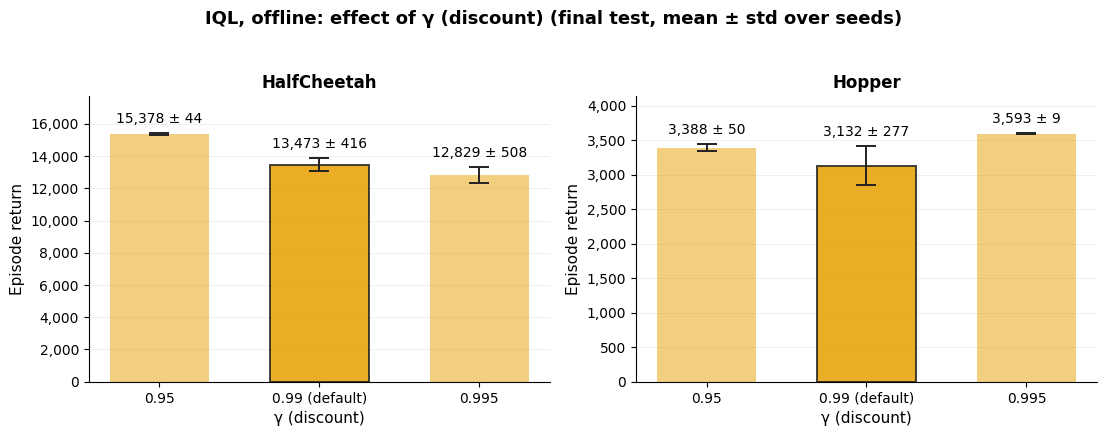

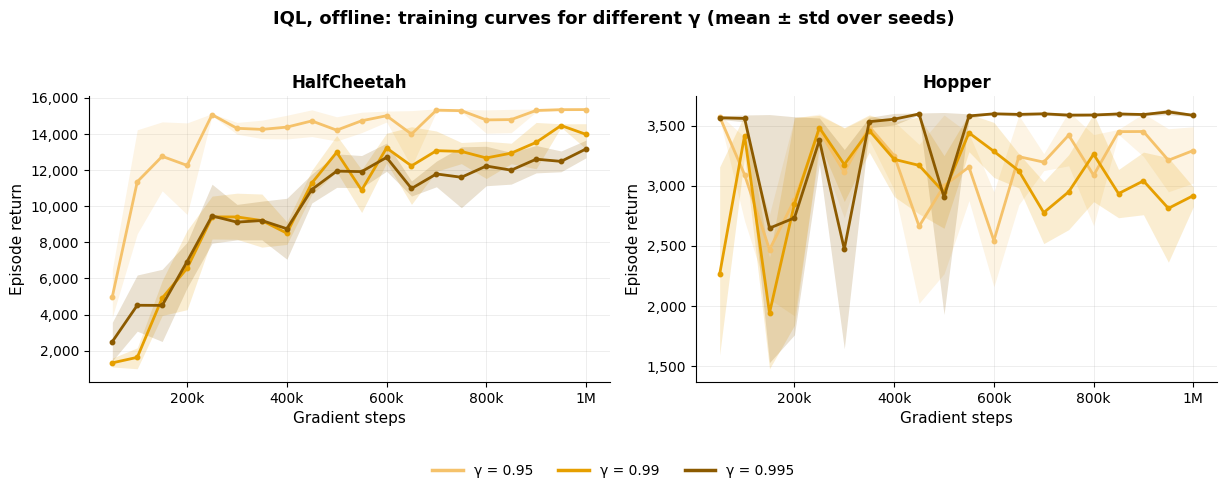

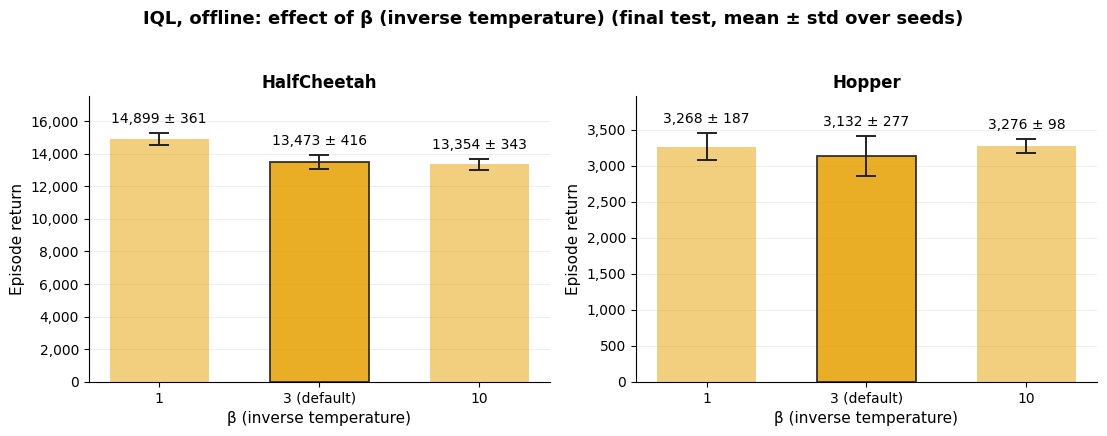

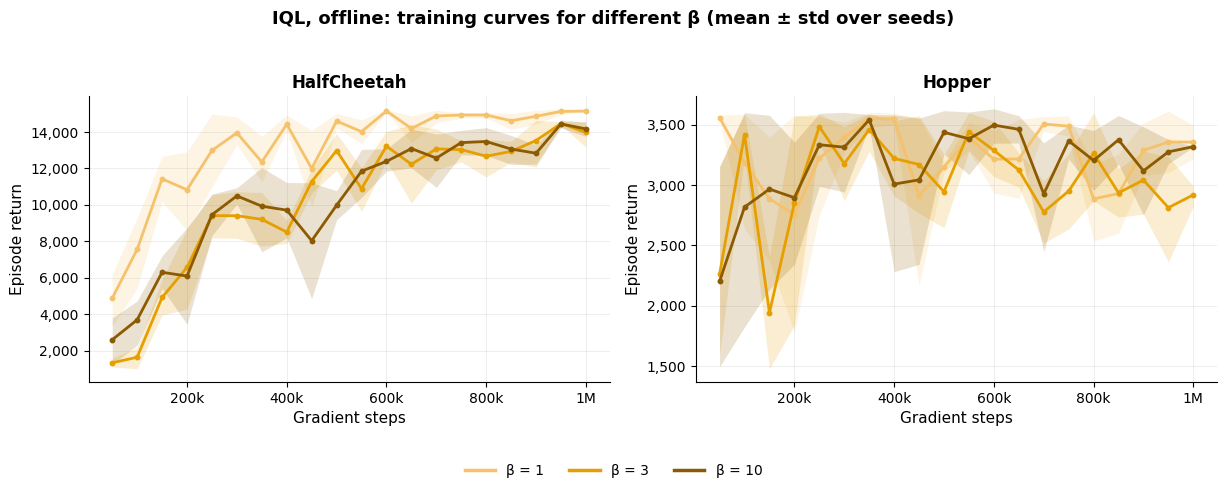

In [7]:
for param in ["discount", "beta"]:
    sel = {name: ablation.by_value(res, param, DEFAULTS) for name, res in RESULTS.items()}
    plotting.plot_ablation(sel, param, default=DEFAULTS[param], save_path=f"{OUT_DIR}/figures/{param}_final.png")
    plotting.plot_ablation_curves(sel, param, save_path=f"{OUT_DIR}/figures/{param}_curves.png")